![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 02 | Pipelines and Models

*Project 2 — Machine Learning: From Data to Predictions*

**Team: Zoé Doucet**
**Dataset: Covertype**

---

Steps 5 to 8 of the workflow: build the pipeline, compare models fairly, tune the best, and choose the threshold. Everything here uses the training set only.

> **Done when:** you have a comparison table of at least three model families on the same folds against the baseline, the best one or two tuned, and a final model chosen for reasons you can state.

The sections below are a suggested route, not a form to fill in. Add sections, drop them, reorder them — what is graded is the work, not whether you kept the scaffold.

---
## 0. Setup

In [ ]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (f1_score, recall_score, precision_score, accuracy_score,
                             classification_report, ConfusionMatrixDisplay, make_scorer)
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold, train_test_split, cross_val_predict
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline, make_pipeline
import io
from contextlib import redirect_stdout
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.model_selection import GridSearchCV

from src.functions import *

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

---
## 1. Load and split

The same loading and the same split as notebook 01. Put the code in `src/functions.py` so both notebooks use exactly the same rows.

In [2]:
covertype= pd.read_csv("../data/covertype_clean.csv") # loading the data

In [3]:
# splitting the data using the split function
X, y, X_train, X_test, y_train, y_test, cv, folds = split( covertype.drop(columns= ["cover_type"]),
                                                    covertype["cover_type"],
                                                    0.25,
                                                    42,
                                                    5)

435759 training rows, 145253 test rows


---
## 2. The preprocessing pipeline

A `ColumnTransformer` with one branch per column type: impute, scale, encode. **Everything that learns from data goes inside**, so cross-validation refits it on every fold.

In [4]:
cat_features = ["soil_type", "wilderness_area"] # creating a lsit with the categorical features
num_features = X.drop(columns = cat_features).columns.tolist() # creating a list with the numerical features

preprocess = ColumnTransformer([
    ("num", 
      StandardScaler(), 
      num_features), # Scaling the numerical features
    ("cat", 
     OneHotEncoder(handle_unknown="ignore", sparse_output=False), 
     cat_features)])# transforming categrorical columns into binary columns


---
## 3. First model in the pipeline

One simple model at the end of the pipeline, scored with cross-validation. Is it better than the baseline, and by more than the spread across folds?

In [50]:
log_reg_1 = Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=1000))])

In [51]:
score_log_reg, spread_log_reg = cross_validation (log_reg_1, X_train, y_train, folds)

Scores: {'f1': np.float64(0.533), 'recall': np.float64(0.512), 'accuracy': np.float64(0.725), 'precision': np.float64(0.604)} 
 Spread: {'f1': np.float64(0.005), 'recall': np.float64(0.005), 'accuracy': np.float64(0.002), 'precision': np.float64(0.008)}


The logistic regressionachieved a mean accuracy of 72.5 % which is higher than the baseline model. The model has an F1-score of 0.533, recall of 0.512, and precision of 0.604. The low standard deviations across folds (0.002–0.008) indicate consistent performance. However, the relatively low F1-score and recall suggest that the model struggles to identify all classes effectively.

---
## 4. Features

New features added inside the pipeline. Keep a feature only if it improves the cross-validated score, and write down what each one changed.

To tune the model three different features will be testetd to see if they improve the model:
- RobustScaler: helps when numerical features contain outliers by scaling using the median and the interquantile range instead of the mean and standard deviation
- PolynomialFeatures: creates interactions between the numerical features and squares them
- SelectKBest: reduces noise and training time by selecting the k best features according to an ANOVA F-test

In [38]:
# RobustScaler
preprocess_robust = ColumnTransformer([
    ("num", 
     RobustScaler(), num_features), # changing the scaler from StandardScaler to RobustScaler
    ("cat", 
     OneHotEncoder(handle_unknown="ignore",sparse_output=True), cat_features)])

log_reg_rbsc = Pipeline([("prep", preprocess_robust),("model", LogisticRegression(max_iter=1000))])

scores_robust, spread_robust = cross_validation(log_reg_rbsc, X_train, y_train, folds)

Scores: {'f1': np.float64(0.532), 'recall': np.float64(0.511), 'accuracy': np.float64(0.725), 'precision': np.float64(0.603)} 
 Spread: {'f1': np.float64(0.005), 'recall': np.float64(0.005), 'accuracy': np.float64(0.002), 'precision': np.float64(0.009)}


In [ ]:
# PolynomialFeatures
# This feature can not be used, as the  model does not converge
log_reg_pol = Pipeline([("prep", preprocess), ("poly", PolynomialFeatures(degree=2, include_bias=False)), ("model", LogisticRegression(solver="lbfgs", max_iter=1000, C=1.0))])
scores_pol, spread_pol = cross_validation(log_reg_pol, X_train, y_train, folds)

In [ ]:
#SelectKBest
best_score = 0
best_k = None
best_model = None

for k in [13, 20, 30, 40, "all"]:
    log_reg_slct = Pipeline([("prep", preprocess),("select", SelectKBest(score_func=f_classif, k=k)),("model", LogisticRegression(max_iter=1000))])

    with redirect_stdout(io.StringIO()): # avoids printing the scores and spread for each k
        scores_slct, spread_slct = cross_validation(log_reg_slct, X_train, y_train, cv)

    if scores_slct["accuracy"] > best_score:
        best_score = scores_slct["accuracy"]
        best_k = k
        best_model = log_reg_slct
print(best_k)

all


The best selection of features includes all the features (k=all).

In [ ]:
models = {
    "Logistic Regression": (score_log_reg, spread_log_reg),
    "RobustScaler": (scores_robust,spread_robust),
    #"PolynomialFeatures": (score_pol, spread_pol), # was taken out because the model does not converge
    "SelectKBest": (scores_slct, spread_slct)}

compare_models (models)

,Model,f1,f1_spread,recall,recall_spread,accuracy,accuracy_spread,precision,precision_spread
0,Logistic Regression,0.533,0.005,0.512,0.005,0.725,0.002,0.604,0.008
1,RobustScaler,0.532,0.005,0.511,0.005,0.725,0.002,0.603,0.009
2,SelectKBest,0.533,0.005,0.512,0.005,0.725,0.002,0.604,0.008


SelectKBest and Logistic Regression are essentially the same because best_k = all.

Logistic Regression is the best model out of the three. No feature is improving it.

---
## 5. Compare models

At least three model families on **the same folds**, with the mean and the spread. A table, and a chart of it.

In [5]:
candidates = {
    "Logistic regression": create_pipeline(preprocess, LogisticRegression(max_iter=1000)),
    "Random forest": create_pipeline(preprocess, RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)),
    "HistGradientBoosting": create_pipeline(preprocess,HistGradientBoostingClassifier(random_state=42)),
    "Decision Tree": create_pipeline(preprocess, DecisionTreeClassifier(max_depth=5,min_samples_leaf=10,random_state=42))}

model_candidates = {}
for name, model in candidates.items():
     with redirect_stdout(io.StringIO()): # supresses printed output
         score, spread = cross_validation(model, X_train, y_train, folds)
     model_candidates[name] = (score, spread)

model_comparison = compare_models(model_candidates)
model_comparison

,Model,f1,f1_spread,recall,recall_spread,accuracy,accuracy_spread,precision,precision_spread
0,Logistic regression,0.533,0.005,0.512,0.005,0.725,0.002,0.604,0.008
1,Random forest,0.916,0.004,0.897,0.005,0.950,0.001,0.940,0.003
2,HistGradientBoosting,0.777,0.040,0.759,0.049,0.822,0.026,0.805,0.023
3,Decision Tree,0.475,0.006,0.459,0.008,0.703,0.002,0.668,0.013


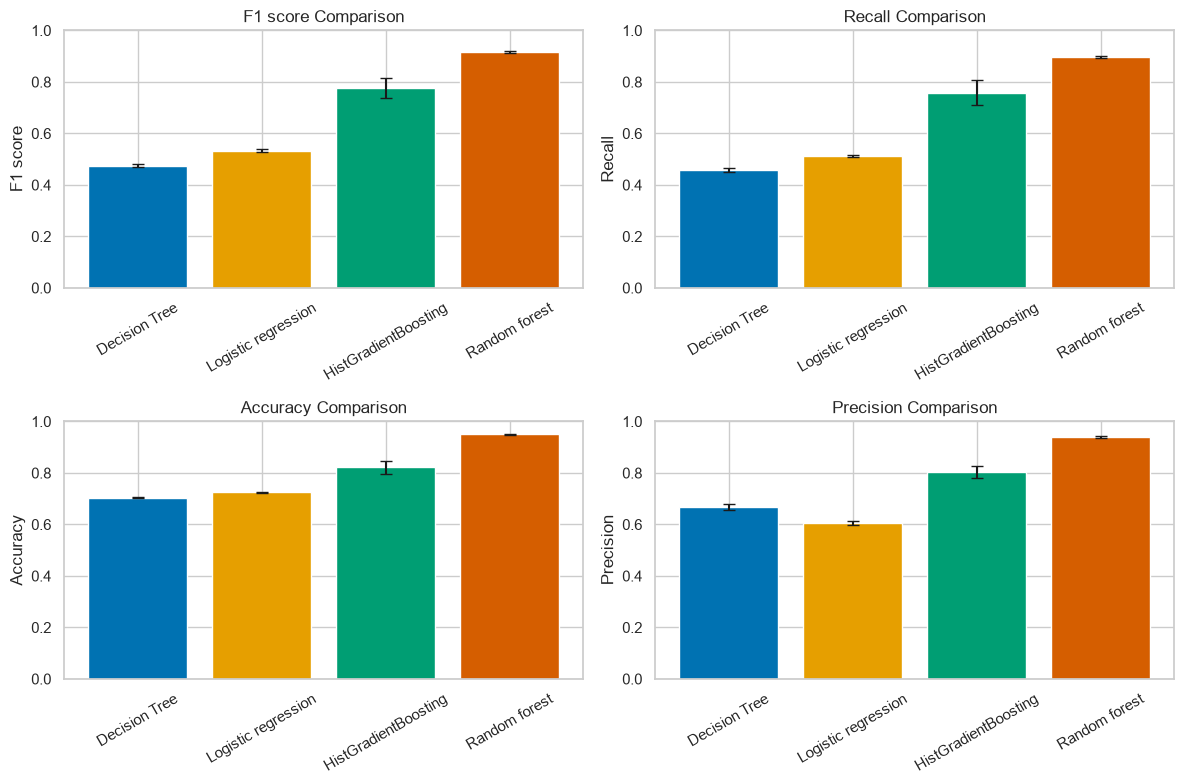

In [6]:
metrics = [("f1", "f1_spread", "F1 score"),
           ("recall", "recall_spread", "Recall"),
            ("accuracy", "accuracy_spread", "Accuracy"),
            ("precision", "precision_spread", "Precision"),]
cross_validation_chart(metrics, model_comparison)

Comparing the model scores and looking at the charts, the **Random Forest** stands out. The model achieves an **accuracy** of **95.0 %**, with a standard deviation of 0.001 across the folds. Precision and recall are also very high, at 0.940 and 0.897, respectively. The F1 score is therefore relatively high at 0.916.

The second-best model is HistGradientBoosting, with an accuracy of 82.2 %. Its F1 score is 0.777, with a standard deviation of 0.026 across the folds. Logistic Regression and the Decision Tree achieve accuracies of 72.5 % and 70.3 %, respectively. Their F1 scores are also considerably lower, at 0.533 and 0.475.

Overall, the **Random Forest performs best across all four metrics** and shows very little variation across the cross-validation folds.

---
## 6. Tune

A `GridSearchCV` or `RandomizedSearchCV` on the best one or two, on the training set. Report the best parameters and the cross-validated score.

In [ ]:
pipe = Pipeline([("preprocessor", preprocess),("model", RandomForestClassifier(random_state=42))])

# Hyperparameter grids for both models
param_grid = [{
        "model": [RandomForestClassifier(random_state=42, n_jobs=1)],
        "model__n_estimators": [100, 300], # number of trees in the forest
        "model__max_depth": [None, 10, 20], # depth ("levels") of the trees
        "model__min_samples_leaf": [1, 5, 10]}, # minimum number of training samples that must be present in each leaf 
    {
        "model": [HistGradientBoostingClassifier(random_state=42)],
        "model__learning_rate": [0.1, 0.2], # how uch each trees changes the prediction
        "model__max_iter": [100, 200], # number of boosting iterations
        "model__max_leaf_nodes": [15, 31], # maximum number of leaf nodes in each tree
        "model__l2_regularization": [0, 1]}] # penalising overly complex models

# Compare models using cross-validation
search = GridSearchCV(pipe, param_grid, cv=folds, scoring="f1_macro", n_jobs=-1, verbose=1)

search.fit(X_train, y_train)

# Display the best results
results = pd.DataFrame(search.cv_results_)
results["model"] = results["param_model"].map(lambda m: type(m).__name__)

results[["model", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score").head(8).round(3)

print("Best settings:", search.best_params_)
print(f"Best cross-validated macro F1: {search.best_score_:.3f}")

best_model = search.best_estimator_

Fitting 5 folds for each of 34 candidates, totalling 170 fits
Best settings: {'model': RandomForestClassifier(n_jobs=1, random_state=42), 'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}
Best cross-validated macro F1: 0.916


In [ ]:
# table to compare the results
results.sort_values("rank_test_score").head(5)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model,param_model__max_depth,param_model__min_samples_leaf,param_model__n_estimators,param_model__l2_regularization,param_model__learning_rate,param_model__max_iter,param_model__max_leaf_nodes,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score,model
1,513.041681,18.488984,43.206260,7.385260,"RandomForestClassifier(n_jobs=1, random_state=42)",None,1.0,300.0,NaN,NaN,NaN,NaN,"{'model': RandomForestClassifier(n_jobs=1, ran...",0.918088,0.916786,0.909414,0.922162,0.915975,0.916485,0.004126,1,RandomForestClassifier
0,164.578644,4.754127,7.653529,1.048730,"RandomForestClassifier(n_jobs=1, random_state=42)",None,1.0,100.0,NaN,NaN,NaN,NaN,"{'model': RandomForestClassifier(n_jobs=1, ran...",0.915526,0.915466,0.909048,0.920378,0.913813,0.914846,0.003637,2,RandomForestClassifier
33,241.812986,9.629352,20.634403,0.633837,HistGradientBoostingClassifier(random_state=42),NaN,NaN,NaN,1.0,0.2,200.0,31.0,{'model': HistGradientBoostingClassifier(rando...,0.902612,0.902398,0.904028,0.907266,0.904684,0.904198,0.001757,3,HistGradientBoostingClassifier
29,312.136187,2.710368,32.252515,1.256786,HistGradientBoostingClassifier(random_state=42),NaN,NaN,NaN,1.0,0.1,200.0,31.0,{'model': HistGradientBoostingClassifier(rando...,0.888199,0.881727,0.880995,0.888221,0.884686,0.884766,0.003072,4,HistGradientBoostingClassifier
3,483.915208,12.206096,17.925984,1.224791,"RandomForestClassifier(n_jobs=1, random_state=42)",None,5.0,300.0,NaN,NaN,NaN,NaN,"{'model': RandomForestClassifier(n_jobs=1, ran...",0.875947,0.876885,0.870395,0.881788,0.873110,0.875625,0.003830,5,RandomForestClassifier


The `GridSearchCV` confirms that The Random Forest Classifier is the best for this dataset. 
The best hyperparameters are: 
- max_depth: None
- min_samples_leaf: 1
- n_estimators: 300

---
## 7. Threshold

Classification only. Cross-validated probabilities on the training set with `cross_val_predict`, then the threshold that fits your metric and the cost of each mistake. Regression: delete this section and say why in the README.

Goal: predict the most accurate forest cover type (high recall and high accuracy)

Cost: wrong classification does not directly have a cost, no real need to change the threshold

Problem: nature is not homogenous, forest cover types might not be as 

In [ ]:
# Out-of-fold predictions
pred_cv = cross_val_predict(best_model, X_train, y_train, cv=folds)

# Evaluates each forest type
print(classification_report(y_train,pred_cv,target_names=[str(c) for c in best_model.classes_],zero_division=0))

              precision    recall  f1-score   support

           1       0.96      0.94      0.95    158880
           2       0.94      0.97      0.96    212476
           3       0.93      0.96      0.95     26816
           4       0.91      0.84      0.87      2060
           5       0.93      0.74      0.83      7120
           6       0.93      0.88      0.91     13025
           7       0.97      0.94      0.96     15382

    accuracy                           0.95    435759
   macro avg       0.94      0.90      0.92    435759
weighted avg       0.95      0.95      0.95    435759



The cross-validated predictions show that the model has high accuracy. Each class is predicted accurately, except for classes 4 and 5. Class 4 has the lowest precision at 0.91, while class 5 has the lowest recall at 0.74, meaning that it has the highest proportion of missed samples. Class 5 also has the lowest F1-score.

In [26]:
# probability for each class
proba_cv = cross_val_predict(best_model, X_train, y_train, cv=folds, method="predict_proba")
proba_table = pd.DataFrame(proba_cv[:10].round(3), columns=[f"Class {c}" for c in best_model.classes_], index=[f"Sample {i+1}" for i in range(10)])

display(proba_table)

,Class 1,Class 2,Class 3,Class 4,Class 5,Class 6,Class 7
Sample 1,0.430,0.567,0.000,0.000,0.003,0.000,0.000
Sample 2,0.050,0.950,0.000,0.000,0.000,0.000,0.000
Sample 3,0.020,0.980,0.000,0.000,0.000,0.000,0.000
Sample 4,0.217,0.783,0.000,0.000,0.000,0.000,0.000
Sample 5,0.997,0.003,0.000,0.000,0.000,0.000,0.000
Sample 6,0.000,0.007,0.877,0.003,0.000,0.113,0.000
Sample 7,0.550,0.423,0.000,0.000,0.000,0.000,0.027
Sample 8,0.030,0.970,0.000,0.000,0.000,0.000,0.000
Sample 9,0.000,0.000,0.960,0.000,0.000,0.040,0.000
Sample 10,0.000,0.003,0.543,0.000,0.000,0.453,0.000


The cross-validated probabilities show that the model mainly predicts cover types 1 and 2 for a few samples. The first sample is classified as type 2 with a probability of 56.7 %, while the second, third, and fourth samples are also classified as type 2 with higher probabilities. The fifth sample is classified as type 1 with a probability of 99.7 %. The model assigns very low probabilities to the other cover types for these samples. However, these probabilities reflect the model's estimates and do not guarantee that the predictions are correct.

Due to the nature of the dataset, misclassifying a forest cover type does not lead to a major mistake. However, it is important to correctly classify as many cover types as possible. Therefore, in the next step, we will experiment with different thresholds to see how they affect the results.

In [ ]:
classes = best_model.classes_
y_true = np.asarray(y_train)
pred_default = classes[np.argmax(proba_cv, axis=1)]

rows = []
for class_label in classes:
    class_idx = np.where(classes == class_label)[0][0]
    actual = (y_true == class_label)

    for threshold in [0.5, 0.25, 0.1, 0.07, 0.05]: # changing the threshhold to 50 %, 25 %, 10 %, 7 % and 5%
        pred = pred_default.copy()
        pred[proba_cv[:, class_idx] >= threshold] = class_label
        predicted = (pred == class_label)

        rows.append({
            "class": class_label,
            "threshold": threshold,
            "recall": recall_score(actual, predicted, zero_division=0),
            "precision": precision_score(actual, predicted, zero_division=0),
            "missed observations": int((actual & ~predicted).sum()),
            "falsely classified observations": int((~actual & predicted).sum())})

thresholds = pd.DataFrame(rows)
display(thresholds.round(3))

,class,threshold,recall,precision,missed observations,falsely classified observations
0,1,0.50,0.937,0.962,10039,5917
1,1,0.25,0.988,0.856,1897,26419
2,1,0.10,0.999,0.681,197,74309
3,1,0.07,0.999,0.624,87,95705
4,1,0.05,1.000,0.577,42,116237
5,2,0.50,0.972,0.944,6039,12228
6,2,0.25,0.995,0.857,1001,35277
7,2,0.10,0.999,0.741,122,74344
8,2,0.07,1.000,0.701,58,90587
9,2,0.05,1.000,0.668,21,105697


Changing the threshold does greatly lower the number of missed observations, but the number of missclassified observations 

---
## 8. The final model

Which model, which parameters, which threshold, and why. If a simpler model is within the noise of the best one, say which you chose and why.

The final model is a RandomForestClassifier model.

The preprocesser includes scaling the data and using a one-hot encoder to convert categrorical columns into binary columns. No feature is improving the model output. 
The best parameters for the model are the following: 
- max_depth: None  
- min_samples_leaf: 1 
- n_estimators: 300
